# Data

In [ ]:
import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
from pandas_datareader import DataReader
from datetime import datetime
import scipy.stats as stats
import yfinance as yf


# df = pd.read_csv('FFFCX_2010.csv',index_col=0,parse_dates=True)
# dt20 = pd.read_csv('FFFDX_2020.csv',index_col=0,parse_dates=True)


In [ ]:
symbol = '^NSEI'
start_date = '2000-01-01'
end_date = '2024-05-01'

#Data import

df = yf.download(symbol, start=start_date, end=end_date)

[*********************100%%**********************]  1 of 1 completed


In [ ]:
df.head()

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,4494.649902,0
2007-09-18,4494.100098,4551.799805,4481.549805,4546.200195,4546.200195,0
2007-09-19,4550.250000,4739.000000,4550.250000,4732.350098,4732.350098,0
2007-09-20,4734.850098,4760.850098,4721.149902,4747.549805,4747.549805,0
2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,4837.549805,0


In [ ]:
ret10=df['Adj Close']/df['Adj Close'].shift(1)-1

In [1]:
# ret20=dt20['Adj Close']/dt20['Adj Close'].shift(1)-1
# ret10=df['Adj Close']/df['Adj Close'].shift(1)-1

In [ ]:
from scipy.stats import kurtosis
print(kurtosis(ret10.values[1:],fisher=False))

18.44369222111381


In [ ]:
# from scipy.stats import kurtosis
# print(kurtosis(ret10.values[1:],fisher=False))
# print(kurtosis(ret20.values[1:],fisher=False))

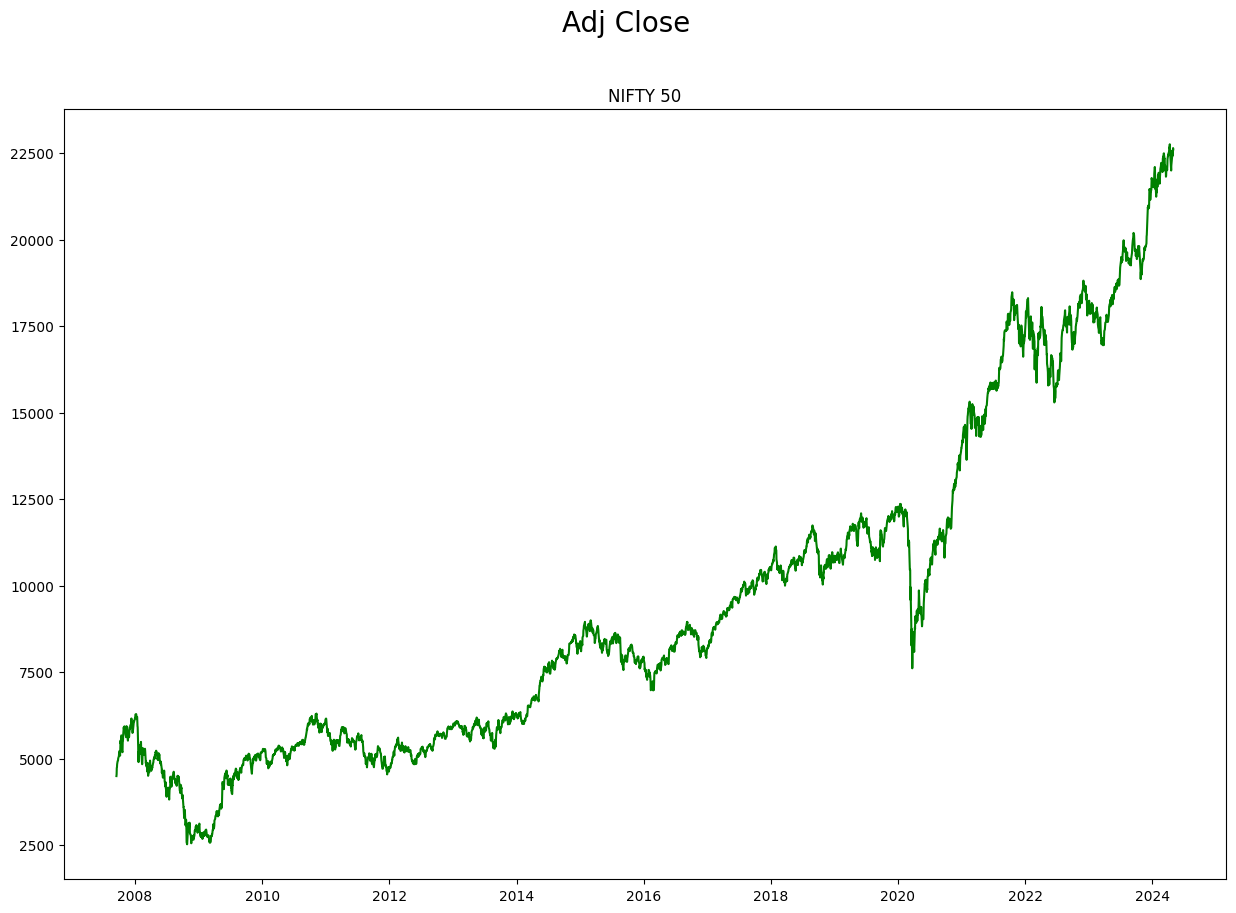

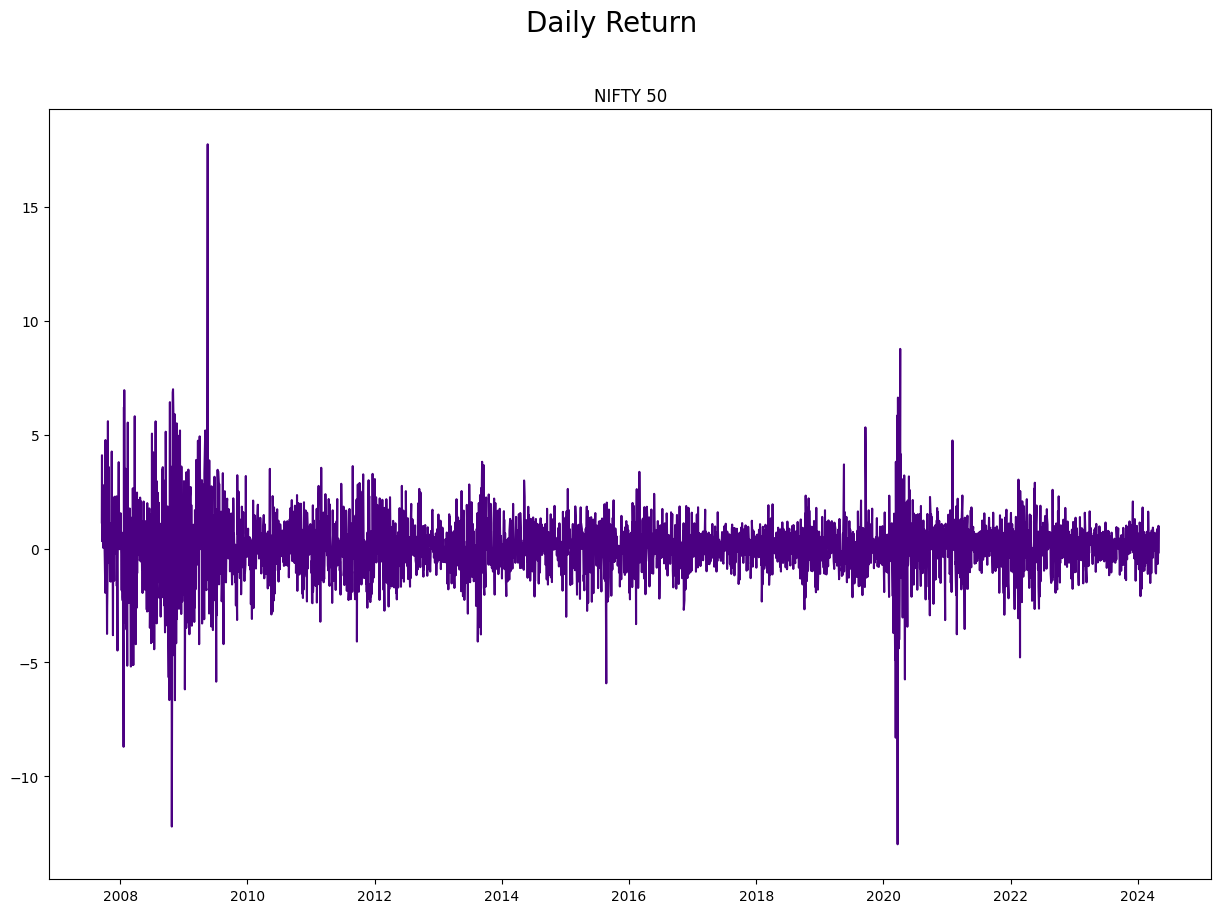

In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Adjusted Close
fig, axs = plt.subplots()
axs.plot(df['Adj Close'], color='green')  # Change color to green
axs.set_title("NIFTY 50")
fig.set_size_inches(15, 10)
plt.suptitle("Adj Close", fontsize=20)
plt.show()

# Plot 2: Daily Returns
fig, axs = plt.subplots()
axs.plot(ret10*100, color='indigo')
axs.set_title("NIFTY 50")
fig.set_size_inches(15, 10)
plt.suptitle("Daily Return", fontsize=20)
plt.show()


In [ ]:
# fig, axs = plt.subplots(2, 1)
# axs.plot(df['Adj Close'])
# axs[1].plot(dt20['Adj Close'])
# axs.set_title("2010 Fund")
# axs[1].set_title("2020 Fund")
# fig.set_size_inches(15, 10)
# plt.suptitle("Adj Close",fontsize=20)
# plt.show()

# fig, axs = plt.subplots(2, 1)
# axs.plot(ret10*100)
# axs[1].plot(ret20*100)
# axs.set_title("2010 Fund")
# axs[1].set_title("2020 Fund")
# fig.set_size_inches(15, 10)
# plt.suptitle("Daily Return",fontsize=20)
# plt.show()

In [ ]:
np.sum(ret10*100<-0.7)

854

In [ ]:
df.shape[0]

4072

# Historical

In [ ]:
def historicalVaR(p):


    pFut10 = 100.*(1.+ret10[1:])
    PStar10 = np.percentile(pFut10,100.*p)
    VaR10=PStar10-100

    return VaR10


In [ ]:
histVaR95=historicalVaR(0.05)
histVaR99=historicalVaR(0.01)

In [ ]:
print(histVaR95)
print()
print(histVaR99)


-1.9190018440994407

-3.7514116173487366


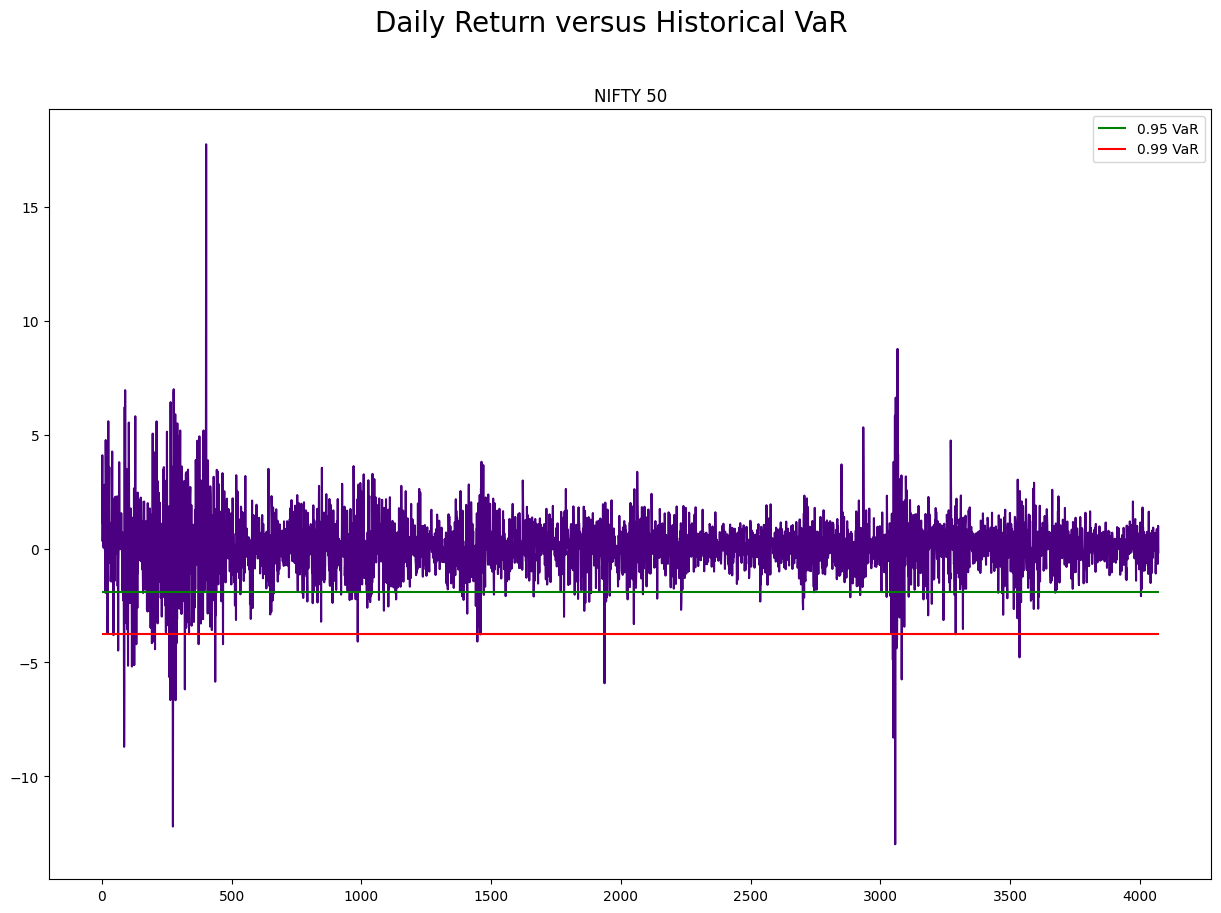

In [ ]:


fig, axs = plt.subplots()
axs.plot(ret10.values*100, color='indigo')
axs.hlines(histVaR95, xmin=0, xmax=4072, label="0.95 VaR", color='green')
axs.hlines(histVaR99, xmin=0, xmax=4072, label="0.99 VaR", color='red')
axs.legend()

axs.set_title("NIFTY 50")
fig.set_size_inches(15, 10)
plt.suptitle("Daily Return versus Historical VaR", fontsize=20)
plt.show()


# Normal

In [ ]:
def normalVaR(p):

    retMean10 = np.mean(ret10)
    retStd10 = np.std(ret10)
    VaR10 = 100*stats.norm.ppf(p,loc=retMean10,scale=retStd10)

    return VaR10

In [ ]:
normalVar95=normalVaR(0.05)
normalVar99=normalVaR(0.01)

In [ ]:
print(normalVar95)
print(normalVar99)

-2.1612241810613106
-3.0768444578438103


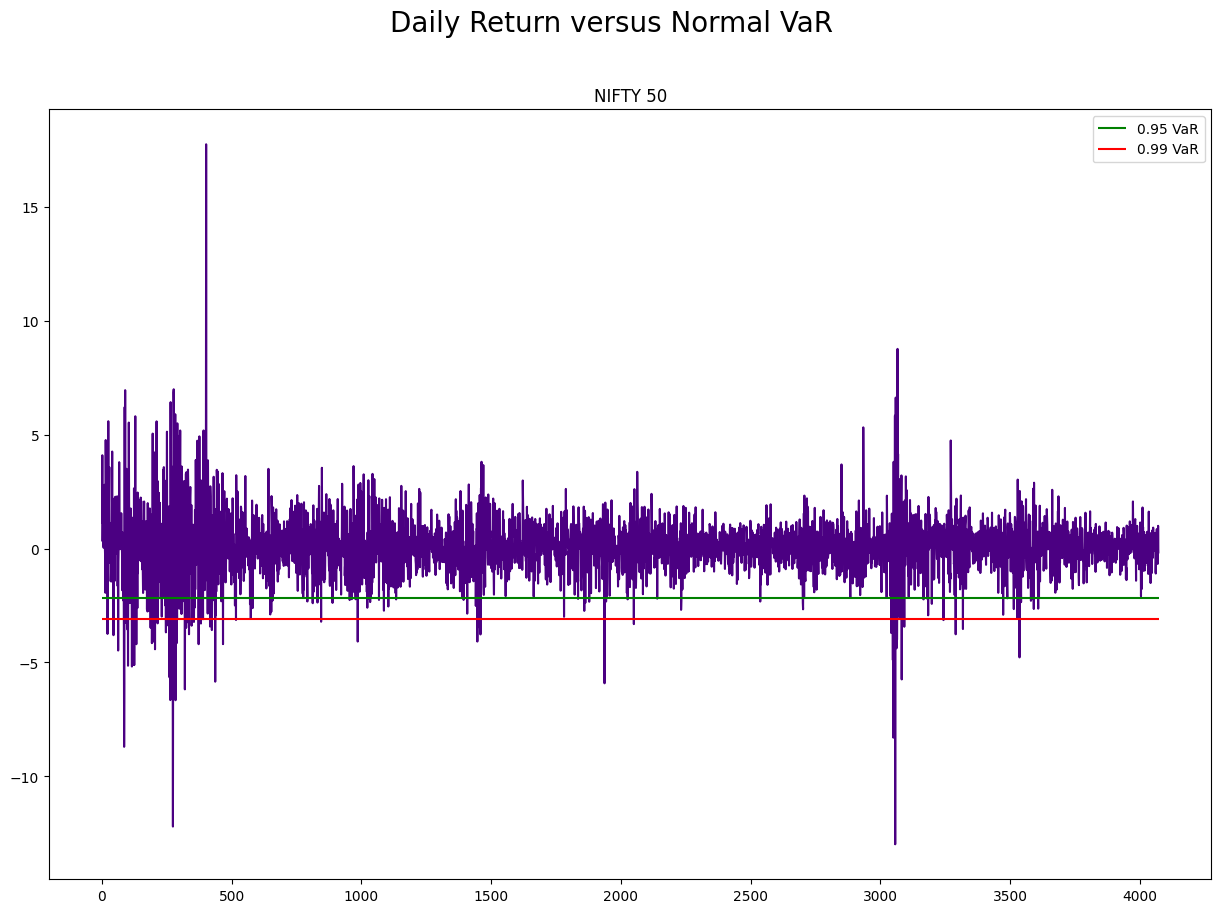

In [ ]:
fig, axs = plt.subplots()
axs.plot(ret10.values*100, color='indigo')
axs.hlines(normalVar95,xmin=0,xmax=4072,label="0.95 VaR",colors='green')
axs.hlines(normalVar99,xmin=0,xmax=4072,label="0.99 VaR",colors='red')
axs.legend()


axs.set_title("NIFTY 50")
fig.set_size_inches(15, 10)

plt.suptitle("Daily Return versus Normal VaR",fontsize=20)

plt.show()

In [ ]:
print(sum(ret10[1:]*100<normalVar95))
print(4072*0.05)
print("")
print(sum(ret10[1:]*100<normalVar99))
print(4072*0.01)

160
203.60000000000002

71
40.72


# Garch

Iteration:      1,   Func. Count:      6,   Neg. LLF: 53739392259008.03
Iteration:      2,   Func. Count:     15,   Neg. LLF: 2225292981.4849887
Iteration:      3,   Func. Count:     22,   Neg. LLF: 6050.5660940873095
Iteration:      4,   Func. Count:     28,   Neg. LLF: 6065.071292491923
Iteration:      5,   Func. Count:     34,   Neg. LLF: 6351.438765624911
Iteration:      6,   Func. Count:     42,   Neg. LLF: 6013.143760315518
Iteration:      7,   Func. Count:     47,   Neg. LLF: 6012.841733217708
Iteration:      8,   Func. Count:     53,   Neg. LLF: 6012.459831936669
Iteration:      9,   Func. Count:     59,   Neg. LLF: 6011.090277182106
Iteration:     10,   Func. Count:     64,   Neg. LLF: 6011.08725453355
Iteration:     11,   Func. Count:     69,   Neg. LLF: 6011.087223560887
Iteration:     12,   Func. Count:     74,   Neg. LLF: 6011.087222219057
Iteration:     13,   Func. Count:     78,   Neg. LLF: 6011.087222218952
Optimization terminated successfully    (Exit mode 0)
         

<ipython-input-186-a069949e125a>:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  simret10[i]=params10[0]/100+np.sqrt(sig10[i])*np.random.normal(0,1,1)/100


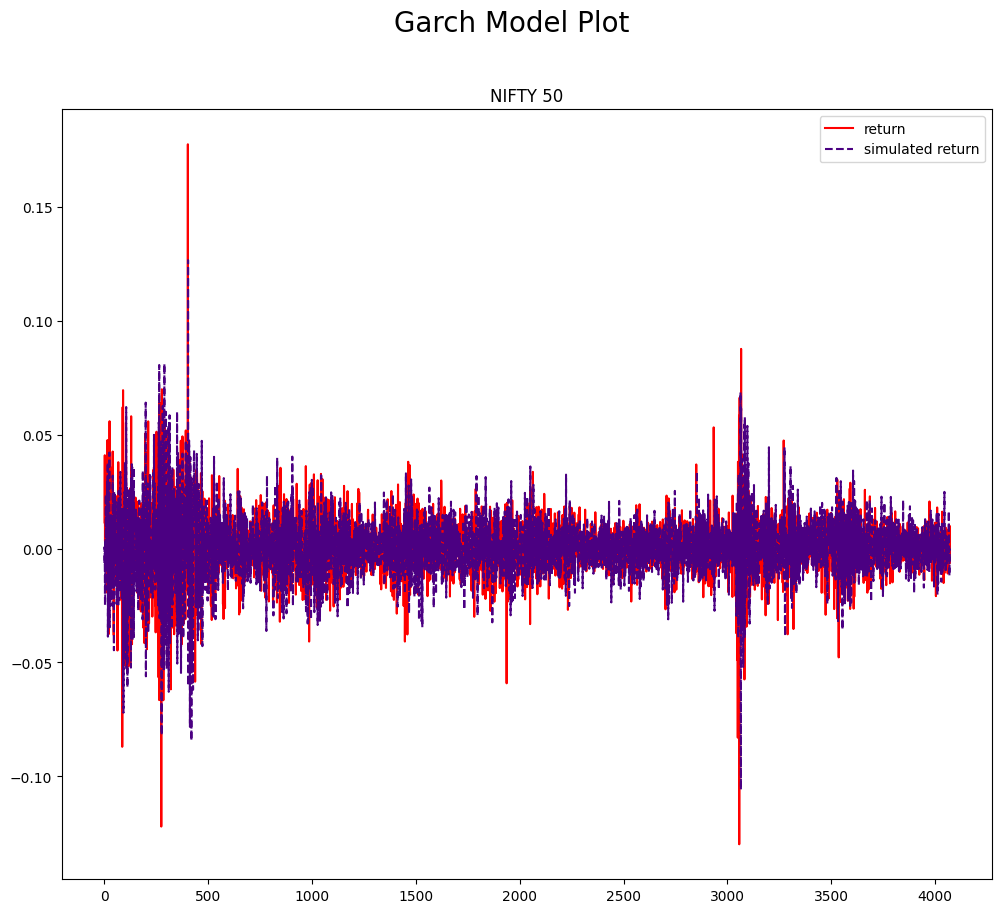

In [ ]:
!pip install arch
from arch import arch_model

garch10=arch_model(ret10[1:]*100).fit()

params10=garch10.params


sig10=np.zeros(df.shape[0])
sig10[0]=params10[1]/(1-params10[3])
sig10[1]=params10[1]/(1-params10[3])
for i in range(1,df.shape[0]-1):
    sig10[i+1]=params10[1]+sig10[i]*params10[3]+params10[2]*(ret10[i]*100-params10[0])*(ret10[i]*100-params10[0])
simret10=np.zeros(df.shape[0])
for i in range(df.shape[0]-1):
    simret10[i]=params10[0]/100+np.sqrt(sig10[i])*np.random.normal(0,1,1)/100
fig, axs = plt.subplots(1, 1)
fig.set_size_inches(12, 10)
axs.plot(ret10.values,'red', label='return')
axs.plot(simret10,'indigo',linestyle='dashed',label='simulated return')
axs.set_title("NIFTY 50")
plt.suptitle("Garch Model Plot",fontsize=20)
plt.legend()
plt.show()






# sig20=np.zeros(dt20.shape[0])
# sig20[0]=params20[1]/(1-params20[3])
# sig20[1]=params20[1]/(1-params20[3])
# for i in range(1,dt20.shape[0]-1):
#     sig20[i+1]=params20[1]+sig20[i]*params20[3]+params20[2]*(ret20[i]*100-params20[0])*(ret20[i]*100-params20[0])
# simret20=np.zeros(dt20.shape[0])
# for i in range(dt20.shape[0]-1):
#     simret20[i]=params20[0]/100+np.sqrt(sig20[i])*np.random.normal(0,1,1)/100
# fig, axs = plt.subplots(1, 1)
# fig.set_size_inches(12, 10)
# axs.plot(ret20.values,'r', label='return')
# axs.plot(simret20,'b',linestyle='dashed',label='simulated return')
# axs.set_title("2020 Fund")
# plt.legend()
# plt.show()





In [ ]:
def garchVaR(p):

    VaR10=np.zeros(df.shape[0])
    for i in range(df.shape[0]-1):
        VaR10[i]=params10[0]/100+np.sqrt(sig10[i])/100*stats.norm.ppf(p,loc=0,scale=1)

    return VaR10*100

In [ ]:
garchVar95=garchVaR(0.05)
garchVar99=garchVaR(0.01)


In [ ]:
print(np.mean(garchVar95[1:]))
print()
print(np.mean(garchVar99[1:]))


-1.853934449111236

-2.6542618199503103


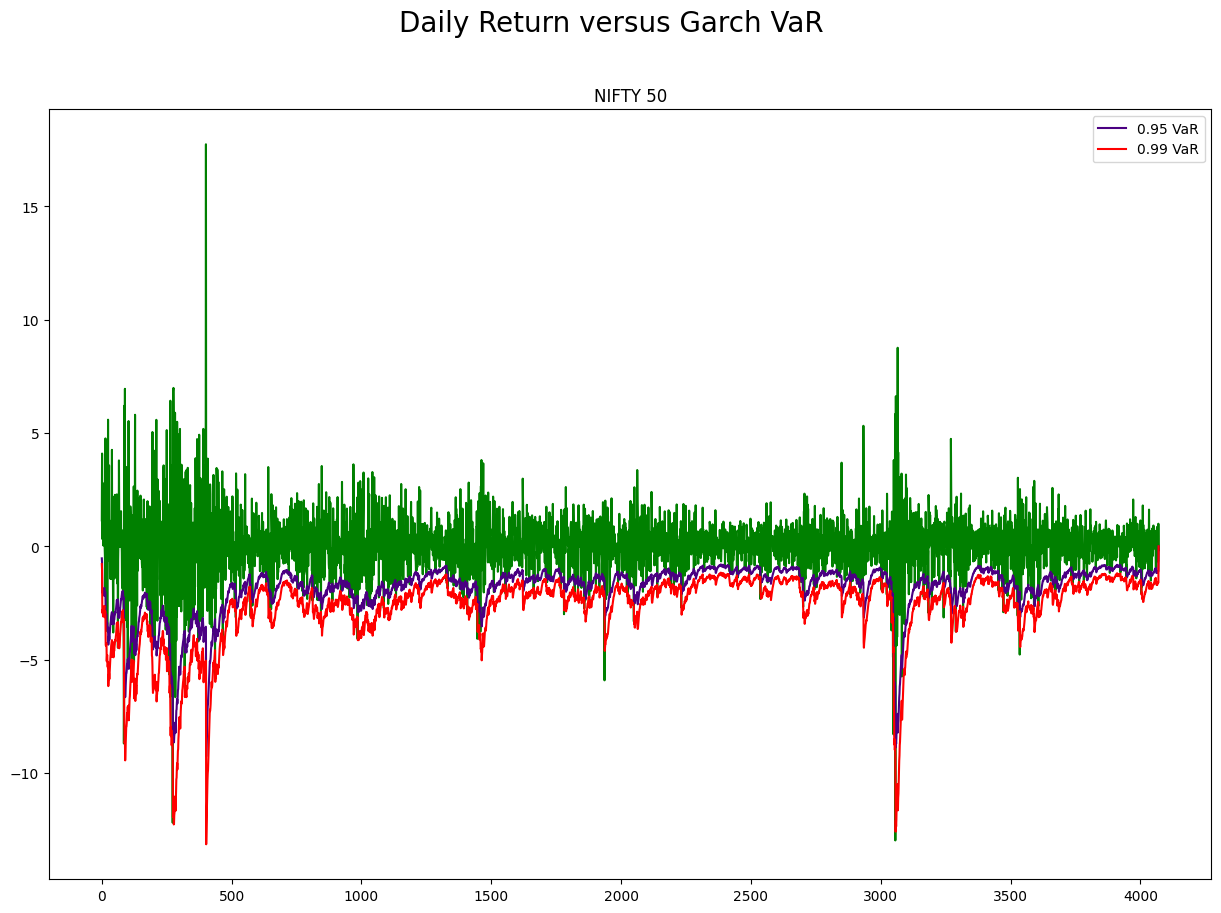

In [ ]:
fig, axs = plt.subplots()
axs.plot(ret10.values[1:]*100, color ='green')
axs.plot(garchVar95[1:],label="0.95 VaR",color='indigo')
axs.plot(garchVar99[1:],label="0.99 VaR",color='red')
axs.legend()

axs.set_title("NIFTY 50")

fig.set_size_inches(15, 10)

plt.suptitle("Daily Return versus Garch VaR",fontsize=20)

plt.show()

In [ ]:
print(sum(ret10[1:-1]*100<garchVar95[1:-1]))
print(4072*0.05)
print("")
print(sum(ret10[1:-1]*100<garchVar99[1:-1]))
print(4072*0.01)




227
203.60000000000002

76
40.72


# ARIMA

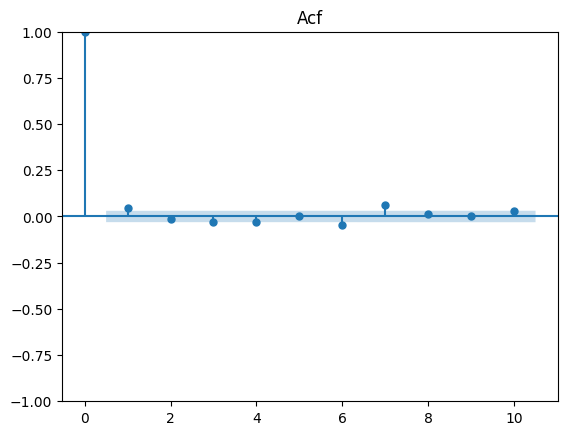

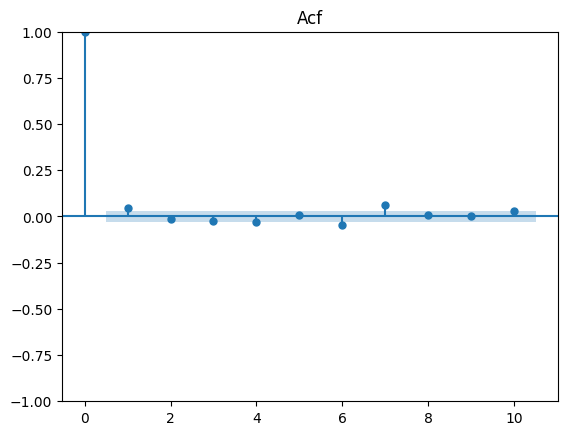

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.graphics.tsaplots import plot_acf

#plot_acf(ret10.values[1:].reshape(-1,1), lags=10)
plot_acf(ret10.values[1:].reshape(-1,1), lags=10)
plt.title("Acf")
plt.show()

#plot_acf(ret10.values[1:].reshape(-1,1), lags=10)
plot_pacf(ret10.values[1:].reshape(-1,1), lags=10)
plt.title("Acf")
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
reg10 = LinearRegression().fit(ret10.values[1:-1].reshape(-1, 1), ret10.values[2:].reshape(-1, 1))
yhat10=reg10.predict(ret10.values[1:-1].reshape(-1, 1))
sig210=np.sum(np.square(yhat10-ret10.values[2:].reshape(-1, 1)))/(ret10.values[1:-1].shape[0]-1)


In [ ]:
def ArimaVaR(p):
    VaR10=yhat10+stats.norm.ppf(p,loc=0,scale=1)*np.sqrt(sig210)
    return VaR10*100

In [ ]:
arimaVar95=ArimaVaR(0.05)
arimaVar99=ArimaVaR(0.01)


In [ ]:
print(np.mean(arimaVar95[1:]))
print()
print(np.mean(arimaVar99[1:]))


-2.159725636413062

-3.0746083206118877


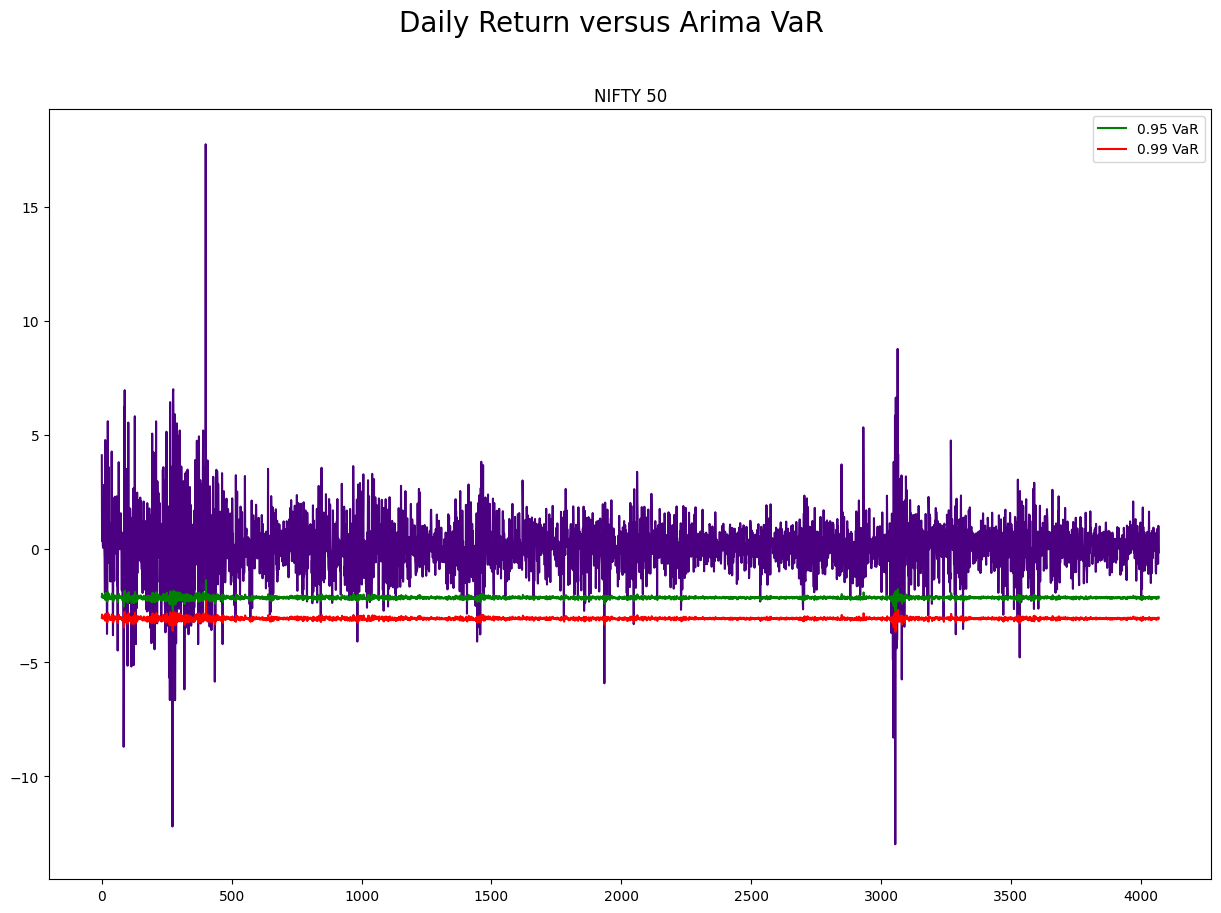

In [ ]:
fig, axs = plt.subplots()
axs.plot(ret10.values[2:]*100, color ='indigo')
axs.plot(arimaVar95.flatten(),label="0.95 VaR",color='green')
axs.plot(arimaVar99.flatten(),label="0.99 VaR",color='red')
axs.legend()


axs.set_title("NIFTY 50")

fig.set_size_inches(15, 10)

plt.suptitle("Daily Return versus Arima VaR",fontsize=20)

plt.show()

In [ ]:
print(sum(ret10[2:]*100<arimaVar95.flatten()))
print(4072*0.05)
print("")
print(sum(ret10[2:]*100<arimaVar99.flatten()))
print(4072*0.01)





156
203.60000000000002

70
40.72


# GPD

In [ ]:
ret10exm=np.sort(ret10[1:])[:300]


In [ ]:
stats.pareto.fit(-ret10exm, 12, loc=0, scale=0.3)

(4.34483437483791, -0.02138832871084577, 0.03721300594439562)

In [ ]:
p=0.05
VaR1095=-stats.pareto.ppf(1-p/0.2,81.30610099869736, -0.24336102575795365, 0.2465278703274249)
VaR2095=-stats.pareto.ppf(1-p/0.2,69.48475579646345, -0.22957449718344247, 0.23216013442897443)

p=0.01
VaR1099=-stats.pareto.ppf(1-p/0.2,81.30610099869736, -0.24336102575795365, 0.2465278703274249)
VaR2099=-stats.pareto.ppf(1-p/0.2,69.48475579646345, -0.22957449718344247, 0.23216013442897443)

In [ ]:
print(VaR1095)
print(VaR2095)
print()
print(VaR1099)
print(VaR2099)

-0.007406260567098644
-0.007263991320121843

-0.012419603914221755
-0.012813778704435008


In [ ]:
print(sum(ret10[1:]*100<VaR1095*100))
print(4072*0.05)
print("")
print(sum(ret10[1:]*100<VaR1099*100))
print(4072*0.01)



817
203.60000000000002

443
40.72


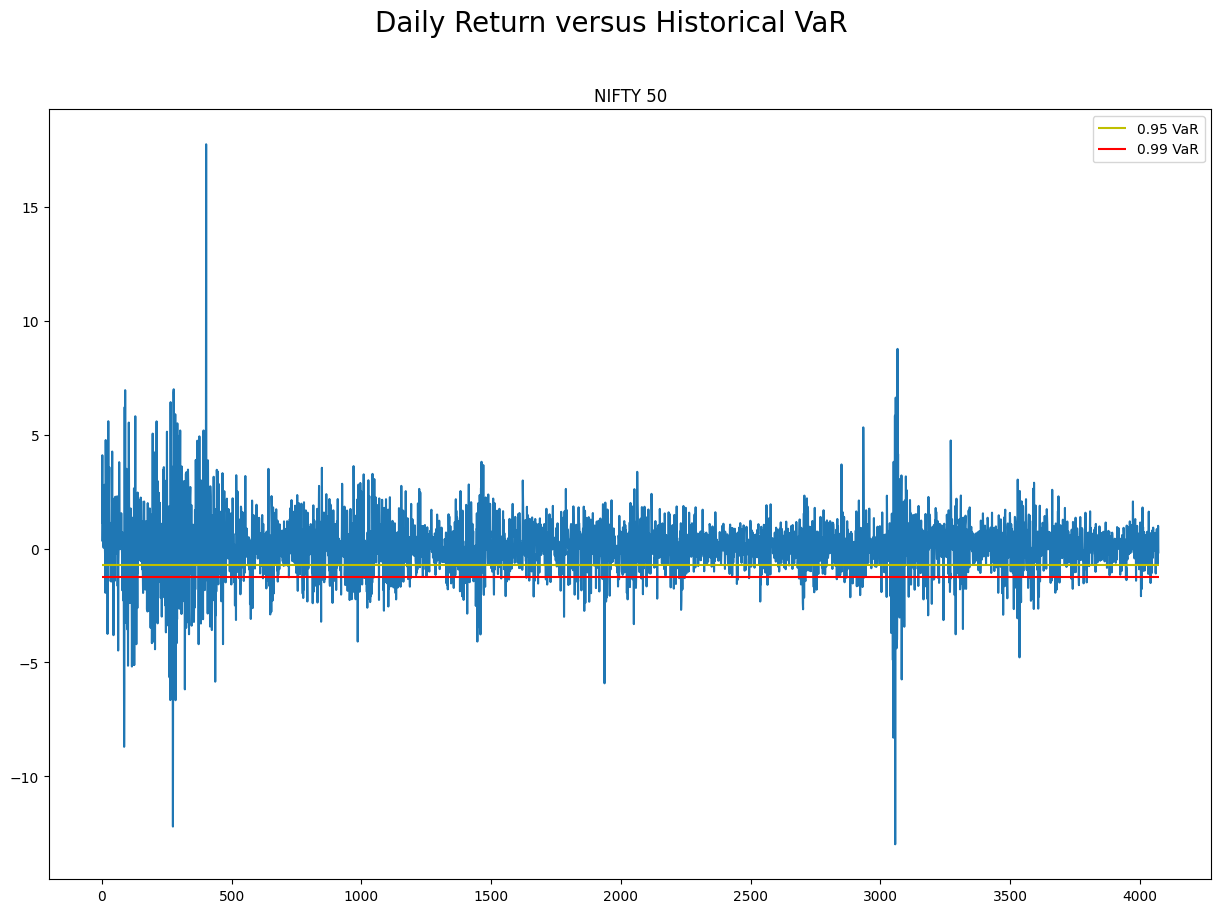

In [ ]:
fig, axs = plt.subplots()
axs.plot(ret10.values*100)
axs.hlines(VaR1095*100,xmin=0,xmax=4072,label="0.95 VaR",colors='y')
axs.hlines(VaR1099*100,xmin=0,xmax=4072,label="0.99 VaR",colors='red')
axs.legend()


axs.set_title("NIFTY 50")

fig.set_size_inches(15, 10)

plt.suptitle("Daily Return versus Historical VaR",fontsize=20)

plt.show()